# 🎓 Student Burnout Risk Prediction

Can daily habits, mental-health scores and academic signals tell us which students are at risk of burnout?

**Dataset:** 150,000 student records with 20 columns (lifestyle, mental health, academic performance) · **Task:** binary classification, *Low* vs. *At-risk* (Medium + High) burnout

**Pipeline:** EDA → statistical signal check → ordinal and one-hot encoding → 6 engineered features → stratified 80/20 split → standardisation → SMOTE (training set only) → 11 classifiers plus a majority-class baseline → comparison by accuracy, precision, recall, F1 and ROC-AUC

> **Headline finding:** none of the features carries information about burnout. Statistical tests find no feature–label association, and all 11 models score ROC-AUC ≈ 0.50 (chance) on held-out data. The notebook shows how to *demonstrate* this rigorously instead of reporting a misleading accuracy.

In [1]:
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, AdaBoostClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import LinearSVC
from sklearn.kernel_approximation import Nystroem
from sklearn.calibration import CalibratedClassifierCV
from sklearn.dummy import DummyClassifier
from scipy.stats import kruskal, chi2_contingency
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, confusion_matrix)
from xgboost import XGBClassifier
from imblearn.over_sampling import SMOTE

warnings.filterwarnings("ignore")
SEED = 42
sns.set_theme(style="whitegrid")
IMG = Path("images"); IMG.mkdir(exist_ok=True)

def save(fig, name):
    fig.savefig(IMG / f"{name}.png", dpi=120, bbox_inches="tight")

## 1. Load and inspect

In [2]:
df = pd.read_csv("student_mental_health_burnout.csv")
print("Shape:", df.shape, "| missing values:", df.isna().sum().sum(), "| duplicate rows:", df.duplicated().sum())
df.head()

Shape: (150000, 20) | missing values: 0 | duplicate rows: 0


,student_id,age,gender,course,year,daily_study_hours,daily_sleep_hours,screen_time_hours,stress_level,anxiety_score,depression_score,academic_pressure_score,financial_stress_score,social_support_score,physical_activity_hours,sleep_quality,attendance_percentage,cgpa,internet_quality,burnout_level
0,100001,23,Male,BTech,1st,4.3,6.8,6.1,High,10,3,4,2,6,1.8,Average,66.5,9.63,Good,High
1,100002,20,Male,BTech,3rd,1.4,4.7,3.0,High,2,10,8,5,9,1.9,Poor,55.8,6.04,Poor,Low
2,100003,24,Female,BCA,4th,3.7,4.8,1.5,Low,2,7,8,6,3,0.8,Good,85.0,8.31,Good,High
3,100004,21,Male,BSc,4th,1.6,6.7,7.0,High,3,3,4,9,9,0.7,Poor,89.1,5.95,Good,High
4,100005,23,Other,BSc,4th,2.0,6.7,5.4,High,7,7,6,4,4,1.7,Good,58.7,8.51,Good,Low


In [3]:
num_cols = df.select_dtypes("number").columns.drop("student_id").tolist()
cat_cols = df.select_dtypes(exclude="number").columns.tolist()
print(f"{len(num_cols)} numeric features:", num_cols)
print(f"{len(cat_cols)} categorical features:", cat_cols)
df.describe().T.round(2)

12 numeric features: ['age', 'daily_study_hours', 'daily_sleep_hours', 'screen_time_hours', 'anxiety_score', 'depression_score', 'academic_pressure_score', 'financial_stress_score', 'social_support_score', 'physical_activity_hours', 'attendance_percentage', 'cgpa']
7 categorical features: ['gender', 'course', 'year', 'stress_level', 'sleep_quality', 'internet_quality', 'burnout_level']


,count,mean,std,min,25%,50%,75%,max
student_id,150000.0,175000.50,43301.41,100001.0,137500.75,175000.50,212500.25,250000.0
age,150000.0,21.00,2.58,17.0,19.00,21.00,23.00,25.0
daily_study_hours,150000.0,5.51,2.60,1.0,3.30,5.50,7.70,10.0
daily_sleep_hours,150000.0,6.50,1.44,4.0,5.20,6.50,7.70,9.0
screen_time_hours,150000.0,6.50,3.18,1.0,3.70,6.50,9.30,12.0
anxiety_score,150000.0,5.49,2.87,1.0,3.00,5.00,8.00,10.0
depression_score,150000.0,5.50,2.87,1.0,3.00,5.00,8.00,10.0
academic_pressure_score,150000.0,5.51,2.88,1.0,3.00,6.00,8.00,10.0
financial_stress_score,150000.0,5.50,2.86,1.0,3.00,6.00,8.00,10.0
social_support_score,150000.0,5.52,2.87,1.0,3.00,6.00,8.00,10.0


## 2. Exploratory data analysis

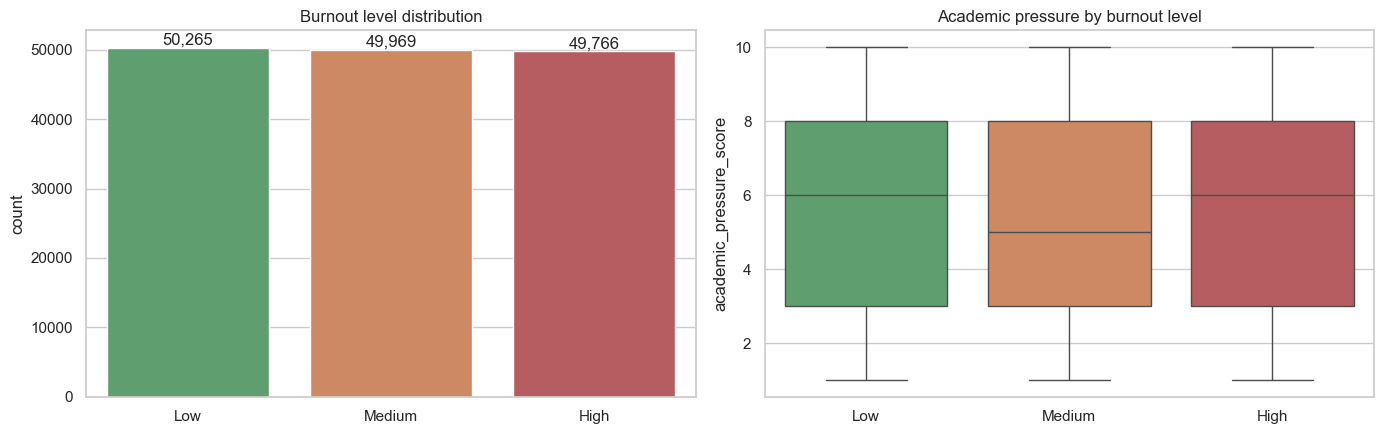

In [4]:
order = ["Low", "Medium", "High"]
palette = {"Low": "#55A868", "Medium": "#DD8452", "High": "#C44E52"}

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
sns.countplot(data=df, x="burnout_level", order=order, palette=palette, ax=axes[0])
axes[0].set_title("Burnout level distribution"); axes[0].set_xlabel("")
for p in axes[0].patches:
    axes[0].annotate(f"{int(p.get_height()):,}", (p.get_x() + p.get_width() / 2, p.get_height()),
                     ha="center", va="bottom")
sns.boxplot(data=df, x="burnout_level", y="academic_pressure_score", order=order, palette=palette, ax=axes[1])
axes[1].set_title("Academic pressure by burnout level"); axes[1].set_xlabel("")
plt.tight_layout(); save(fig, "eda_target_and_pressure"); plt.show()

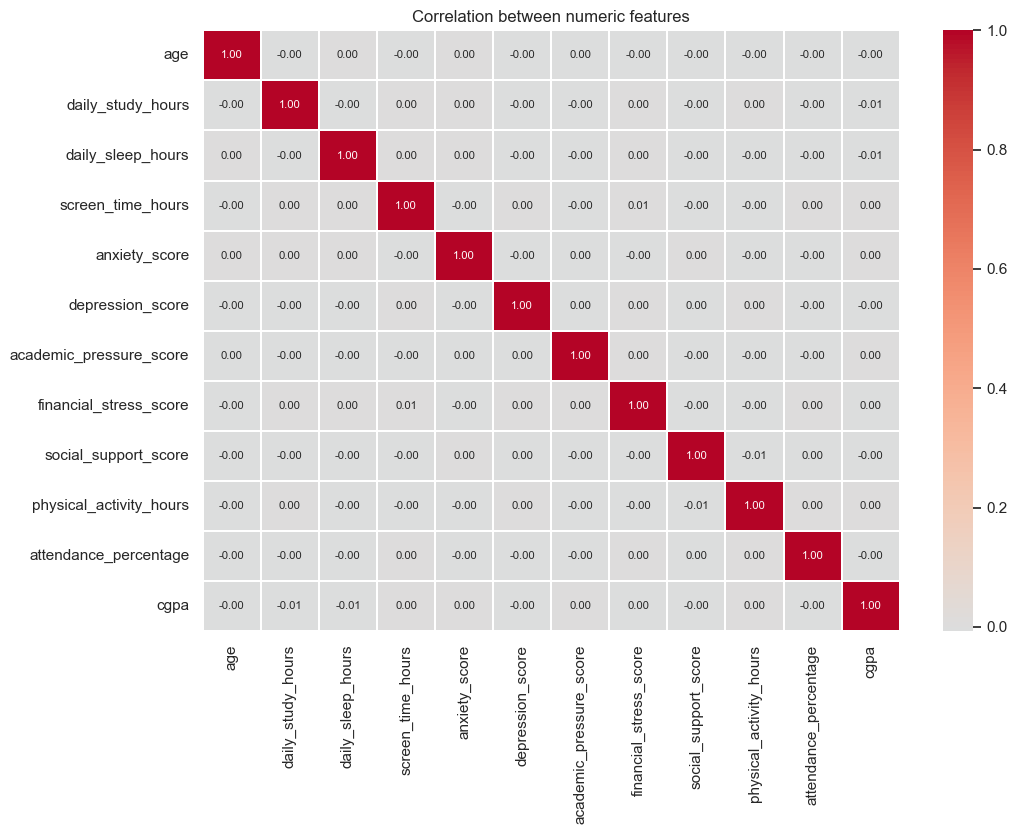

In [5]:
fig, ax = plt.subplots(figsize=(11, 8.5))
sns.heatmap(df[num_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, linewidths=0.3,
            annot_kws={"size": 8}, ax=ax)
ax.set_title("Correlation between numeric features")
plt.tight_layout(); save(fig, "correlation_heatmap"); plt.show()

In [6]:
# How much does the mean of each numeric feature shift across burnout levels?
means = df.groupby("burnout_level")[num_cols].mean().loc[order]
(means.T.assign(**{"High − Low": means.loc["High"] - means.loc["Low"]})
      .sort_values("High − Low", key=abs, ascending=False).round(3))

burnout_level,Low,Medium,High,High − Low
attendance_percentage,75.071,74.965,74.992,-0.080
academic_pressure_score,5.500,5.496,5.526,0.026
screen_time_hours,6.516,6.499,6.493,-0.024
anxiety_score,5.500,5.495,5.486,-0.014
daily_sleep_hours,6.503,6.503,6.492,-0.012
age,21.010,20.990,21.001,-0.010
financial_stress_score,5.495,5.491,5.502,0.008
depression_score,5.490,5.504,5.497,0.007
social_support_score,5.519,5.515,5.514,-0.006
cgpa,6.999,6.997,6.996,-0.003


### Is there any signal to learn?
Before modelling, test every feature for association with burnout level: **Kruskal–Wallis** for numeric features (do the three groups have different distributions?) and a **χ² test of independence** for categorical ones. With 150,000 rows these tests can detect even tiny effects, so a non-significant result is strong evidence of no relationship.

In [7]:
tests = []
for c in num_cols:
    stat, p = kruskal(*[g[c].values for _, g in df.groupby("burnout_level")])
    tests.append({"feature": c, "test": "Kruskal–Wallis", "statistic": stat, "p_value": p})
for c in [c for c in cat_cols if c != "burnout_level"]:
    chi2, p, _, _ = chi2_contingency(pd.crosstab(df[c], df["burnout_level"]))
    tests.append({"feature": c, "test": "χ² independence", "statistic": chi2, "p_value": p})
tests = pd.DataFrame(tests).sort_values("p_value").reset_index(drop=True)
alpha = 0.05 / len(tests)   # Bonferroni correction
tests["significant (Bonferroni)"] = tests["p_value"] < alpha
print(f"{tests['significant (Bonferroni)'].sum()} of {len(tests)} features are significantly associated "
      f"with burnout level at α = 0.05 (Bonferroni-corrected threshold {alpha:.4f}).")
tests.round(4)

0 of 18 features are significantly associated with burnout level at α = 0.05 (Bonferroni-corrected threshold 0.0028).


,feature,test,statistic,p_value,significant (Bonferroni)
0,sleep_quality,χ² independence,7.2404,0.1237,False
1,academic_pressure_score,Kruskal–Wallis,3.1619,0.2058,False
2,gender,χ² independence,5.2386,0.2637,False
3,daily_sleep_hours,Kruskal–Wallis,2.1541,0.3406,False
4,internet_quality,χ² independence,4.1907,0.3808,False
5,physical_activity_hours,Kruskal–Wallis,1.7739,0.4119,False
6,age,Kruskal–Wallis,1.5212,0.4674,False
7,screen_time_hours,Kruskal–Wallis,1.4966,0.4732,False
8,attendance_percentage,Kruskal–Wallis,1.4670,0.4802,False
9,stress_level,χ² independence,3.0363,0.5518,False


## 3. Preprocessing and feature engineering
- **Ordinal encoding** for ordered categories (stress level, sleep quality, internet quality, year)
- **Engineered features:** a mental-health index, lifestyle balance, an academic stress index, a support-to-stress ratio, a performance score and sleep efficiency
- **One-hot encoding** for the remaining categoricals
- **Target:** `Low` → 0, `Medium`/`High` → 1 (*at risk*)

In [8]:
data = df.drop(columns="student_id").copy()
lmh = {"Low": 0, "Medium": 1, "High": 2}
pag = {"Poor": 0, "Average": 1, "Good": 2}
data["stress_level"] = data["stress_level"].map(lmh)
data["sleep_quality"] = data["sleep_quality"].map(pag)
data["internet_quality"] = data["internet_quality"].map(pag)
data["year"] = data["year"].map({"1st": 0, "2nd": 1, "3rd": 2, "4th": 3})

data["mental_health_index"] = (data["anxiety_score"] + data["depression_score"]) / 2
data["lifestyle_balance"] = data["daily_sleep_hours"] + data["physical_activity_hours"] - data["screen_time_hours"]
data["academic_stress_index"] = data["academic_pressure_score"] + data["daily_study_hours"]
data["support_stress_ratio"] = data["social_support_score"] / (data["financial_stress_score"] + 1)
data["performance_score"] = data["cgpa"] * data["attendance_percentage"]
data["sleep_efficiency"] = data["daily_sleep_hours"] * data["sleep_quality"]

data = pd.get_dummies(data, columns=["gender", "course", "year", "stress_level", "sleep_quality",
                                     "internet_quality"], drop_first=True, dtype=int)
y = (data.pop("burnout_level").map(lmh) > 0).astype(int)
X = data
print("Feature matrix:", X.shape)
print("Target balance (1 = at risk):", y.value_counts(normalize=True).round(3).to_dict())

Feature matrix: (150000, 34)
Target balance (1 = at risk): {1: 0.665, 0: 0.335}


In [9]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=SEED, stratify=y)

scaler = StandardScaler().fit(X_train)
X_train_s, X_test_s = scaler.transform(X_train), scaler.transform(X_test)

# Balance only the training data so the test set keeps the real class ratio
X_res, y_res = SMOTE(random_state=SEED).fit_resample(X_train_s, y_train)
print(f"Train: {X_train.shape[0]:,} → after SMOTE: {X_res.shape[0]:,} (balanced)")
print(f"Test:  {X_test.shape[0]:,} (untouched, {y_test.mean():.1%} at risk)")

Train: 120,000 → after SMOTE: 159,576 (balanced)
Test:  30,000 (untouched, 66.5% at risk)


## 4. Models
Eleven classifiers covering linear, instance-based, tree, ensemble, probabilistic, kernel and neural approaches. All of them use a fixed seed.

The original Colab version trained the SVMs on the GPU with RAPIDS cuML. To keep this notebook runnable on any CPU, the **linear SVM** uses `LinearSVC`, and the **RBF SVM** uses a Nyström kernel approximation (1,000 components) followed by a linear SVM. Both are wrapped in `CalibratedClassifierCV` so they output probabilities for ROC-AUC.

In [10]:
def svm_rbf():
    return CalibratedClassifierCV(make_pipeline(Nystroem(kernel="rbf", n_components=1000, random_state=SEED),
                                                LinearSVC(class_weight="balanced", random_state=SEED)), cv=3)

models = {
    "Majority-class baseline": DummyClassifier(strategy="most_frequent"),
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=SEED),
    "KNN": KNeighborsClassifier(n_jobs=-1),
    "Decision Tree": DecisionTreeClassifier(random_state=SEED),
    "Random Forest": RandomForestClassifier(n_jobs=-1, random_state=SEED),
    "MLP": MLPClassifier(max_iter=200, early_stopping=True, random_state=SEED),
    "Naive Bayes": GaussianNB(),
    "Gradient Boosting": GradientBoostingClassifier(random_state=SEED),
    "AdaBoost": AdaBoostClassifier(random_state=SEED),
    "SVM (Linear)": CalibratedClassifierCV(LinearSVC(class_weight="balanced", random_state=SEED), cv=3),
    "SVM (RBF, Nyström)": svm_rbf(),
    "XGBoost": XGBClassifier(eval_metric="logloss", n_jobs=-1, random_state=SEED),
}

## 5. Train and evaluate

In [11]:
rows, probs, preds = [], {}, {}
for name, model in models.items():
    t0 = time.perf_counter()
    if name == "Majority-class baseline":
        model.fit(X_train_s, y_train)
    else:
        model.fit(X_res, y_res)
    fit_s = time.perf_counter() - t0
    p = model.predict_proba(X_test_s)[:, 1]
    # The baseline is fitted on the original (imbalanced) training labels; SMOTE would make it a coin flip
    yhat = (p >= 0.5).astype(int) if name != "Majority-class baseline" else model.predict(X_test_s)
    probs[name], preds[name] = p, yhat
    rows.append({"Model": name,
                 "Accuracy": accuracy_score(y_test, yhat),
                 "Precision": precision_score(y_test, yhat),
                 "Recall": recall_score(y_test, yhat),
                 "F1": f1_score(y_test, yhat),
                 "ROC-AUC": roc_auc_score(y_test, p),
                 "Train time (s)": fit_s})
    print(f"{name:<22} acc={rows[-1]['Accuracy']:.4f}  f1={rows[-1]['F1']:.4f}  "
          f"auc={rows[-1]['ROC-AUC']:.4f}  ({fit_s:.1f}s)")

results = pd.DataFrame(rows).set_index("Model").sort_values("ROC-AUC", ascending=False)
results.to_csv("results.csv", float_format="%.4f")
results.style.format("{:.4f}").format("{:.1f}", subset=["Train time (s)"]) \
       .background_gradient(cmap="Greens", subset=["Accuracy", "F1", "ROC-AUC"])

Majority-class baseline acc=0.6649  f1=0.7987  auc=0.5000  (0.0s)


Logistic Regression    acc=0.4990  f1=0.5680  auc=0.4997  (0.5s)


KNN                    acc=0.4901  f1=0.5527  auc=0.5011  (0.0s)


Decision Tree          acc=0.5477  f1=0.6537  auc=0.5013  (8.3s)


Random Forest          acc=0.6598  f1=0.7938  auc=0.4995  (29.5s)


...

AdaBoost               acc=0.5260  f1=0.6198  auc=0.4982  (29.8s)


SVM (Linear)           acc=0.5003  f1=0.5712  auc=0.4986  (3.7s)


SVM (RBF, Nyström)     acc=0.5501  f1=0.6574  auc=0.5004  (296.7s)


XGBoost                acc=0.6597  f1=0.7936  auc=0.4979  (3.1s)


,Accuracy,Precision,Recall,F1,ROC-AUC,Train time (s)
Model,,,,,,
MLP,0.5893,0.6651,0.7702,0.7138,0.5023,81.7
Decision Tree,0.5477,0.6658,0.6420,0.6537,0.5013,8.3
KNN,0.4901,0.6631,0.4739,0.5527,0.5011,0.0
"SVM (RBF, Nyström)",0.5501,0.6658,0.6492,0.6574,0.5004,296.7
Majority-class baseline,0.6649,0.6649,1.0000,0.7987,0.5000,0.0
Logistic Regression,0.4990,0.6657,0.4953,0.5680,0.4997,0.5
Random Forest,0.6598,0.6649,0.9846,0.7938,0.4995,29.5
Gradient Boosting,0.6377,0.6644,0.9194,0.7714,0.4990,129.3
SVM (Linear),0.5003,0.6650,0.5007,0.5712,0.4986,3.7


## 6. Visual comparison

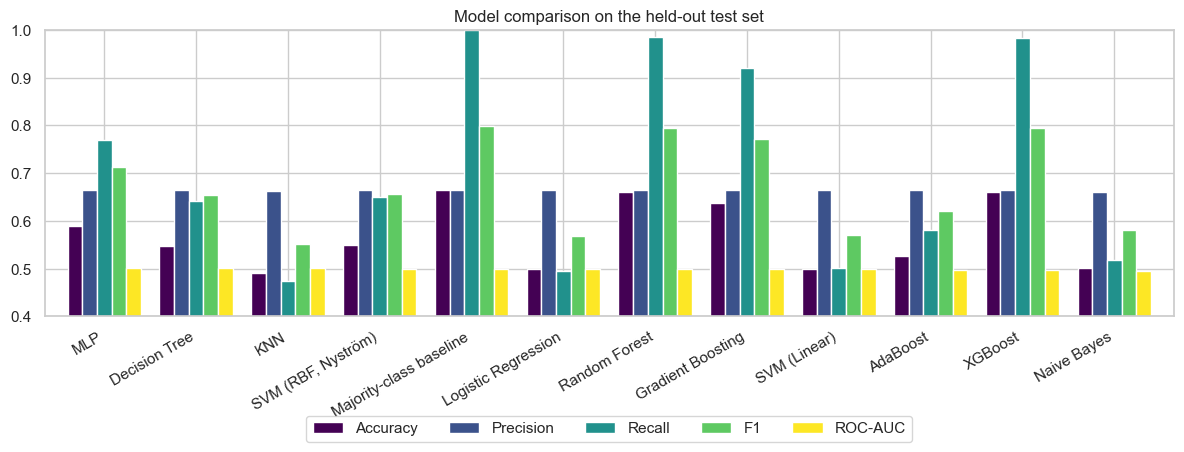

In [12]:
fig, ax = plt.subplots(figsize=(12, 5))
results[["Accuracy", "Precision", "Recall", "F1", "ROC-AUC"]].plot(kind="bar", ax=ax, width=0.8, colormap="viridis")
ax.set_ylim(0.4, 1.0); ax.set_xlabel(""); ax.set_title("Model comparison on the held-out test set")
ax.legend(ncol=5, loc="upper center", bbox_to_anchor=(0.5, -0.32)); plt.xticks(rotation=30, ha="right")
plt.tight_layout(); save(fig, "model_comparison"); plt.show()

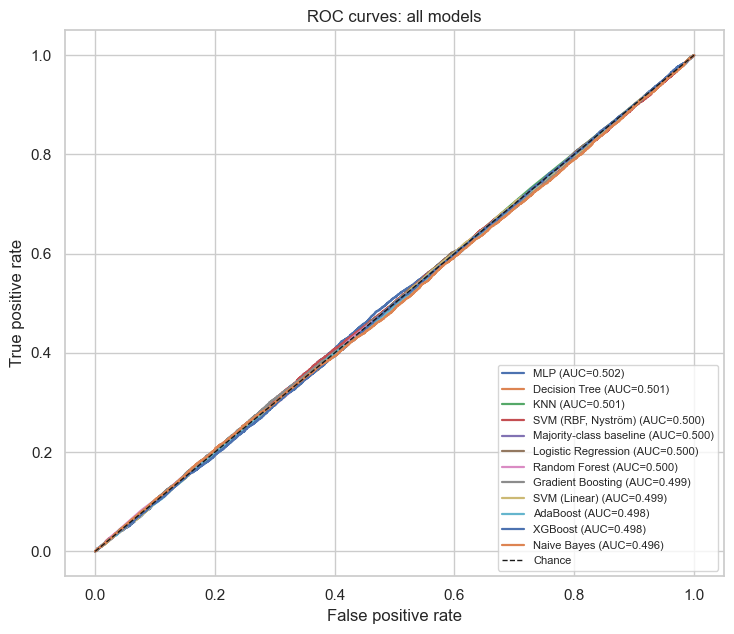

In [13]:
fig, ax = plt.subplots(figsize=(7.5, 6.5))
for name in results.index:
    fpr, tpr, _ = roc_curve(y_test, probs[name])
    ax.plot(fpr, tpr, lw=1.6, label=f"{name} (AUC={results.loc[name, 'ROC-AUC']:.3f})")
ax.plot([0, 1], [0, 1], "k--", lw=1, label="Chance")
ax.set_xlabel("False positive rate"); ax.set_ylabel("True positive rate"); ax.set_title("ROC curves: all models")
ax.legend(fontsize=8, loc="lower right")
plt.tight_layout(); save(fig, "roc_curves"); plt.show()

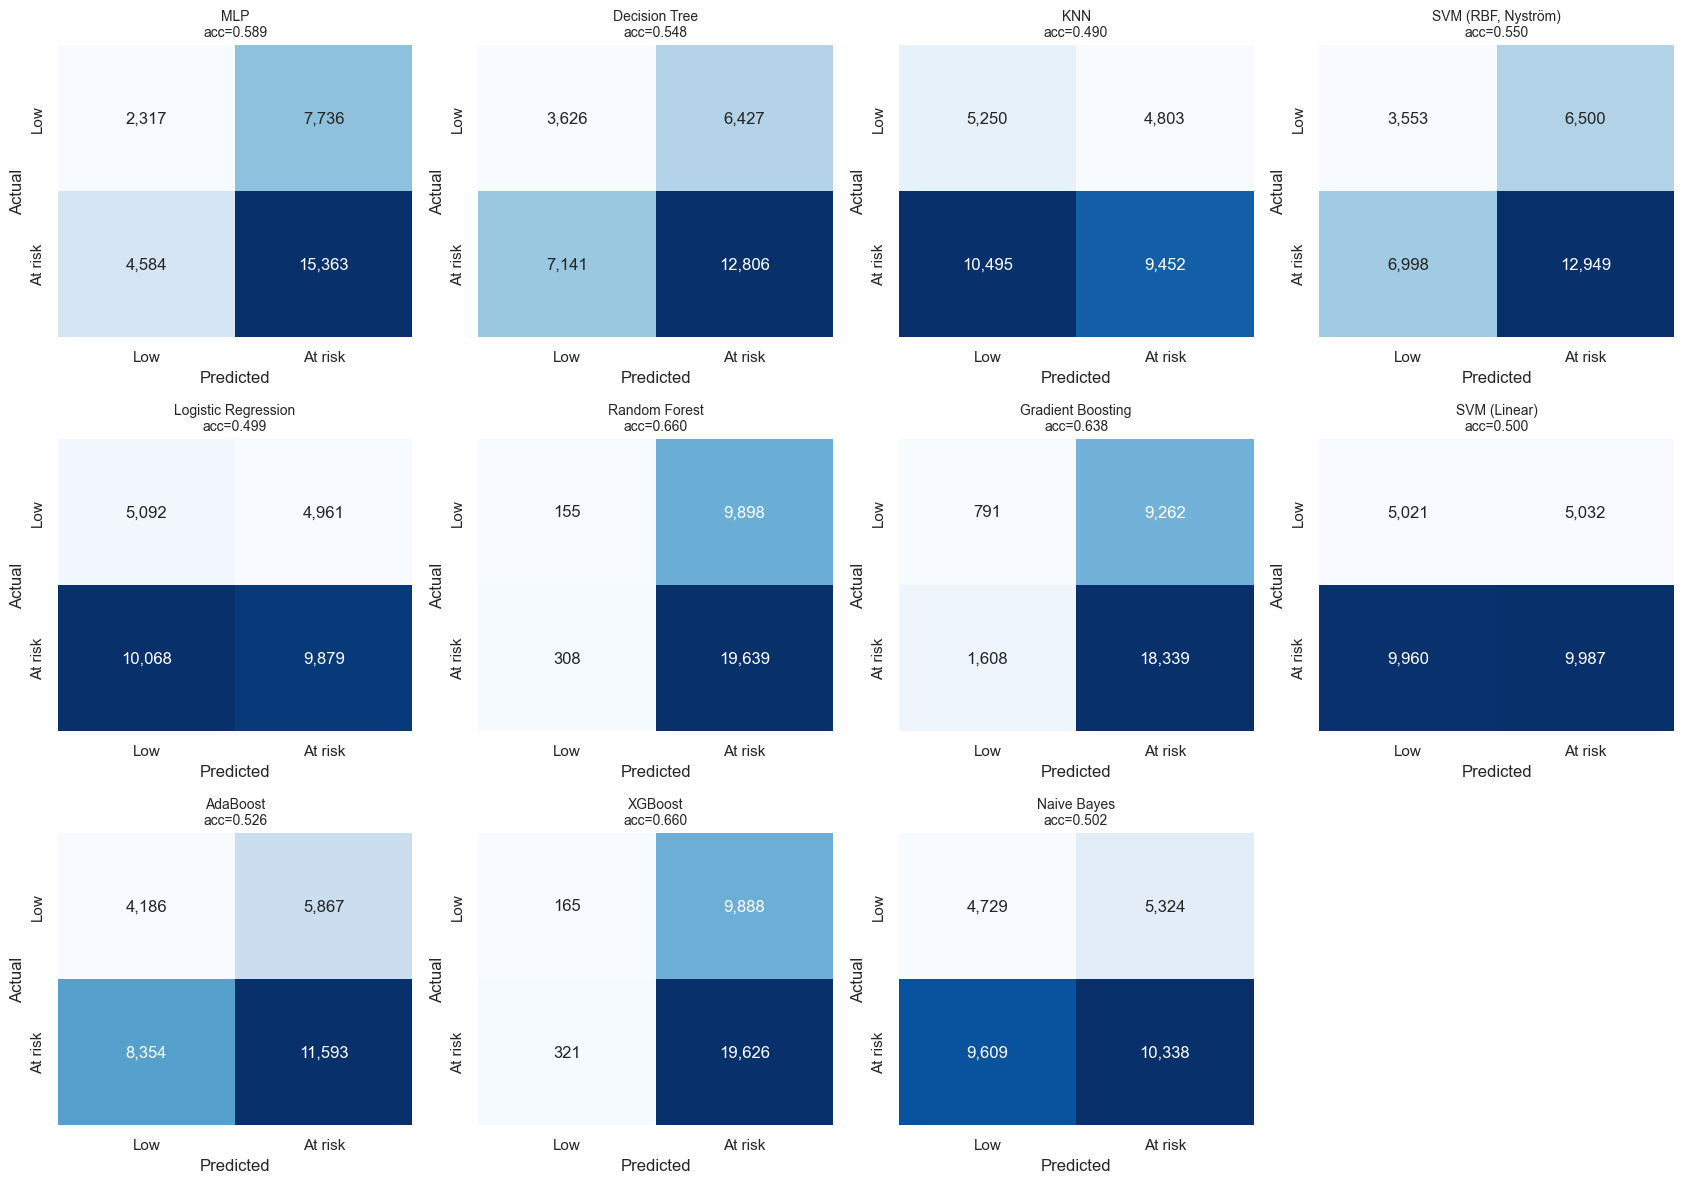

In [14]:
fig, axes = plt.subplots(3, 4, figsize=(17, 12))
cm_models = [m for m in results.index if m != "Majority-class baseline"]
for ax, name in zip(axes.flat, cm_models):
    cm = confusion_matrix(y_test, preds[name])
    sns.heatmap(cm, annot=True, fmt=",", cmap="Blues", cbar=False, ax=ax,
                xticklabels=["Low", "At risk"], yticklabels=["Low", "At risk"])
    ax.set_title(f"{name}\nacc={results.loc[name, 'Accuracy']:.3f}", fontsize=10)
    ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
for ax in axes.flat[len(cm_models):]:
    ax.axis("off")
plt.tight_layout(); save(fig, "confusion_matrices"); plt.show()

## 7. What drives the predictions?
With no real signal, tree-model "importance" mostly reflects which continuous features offer the most split points to fit noise. It is shown here as a cautionary example rather than as insight.

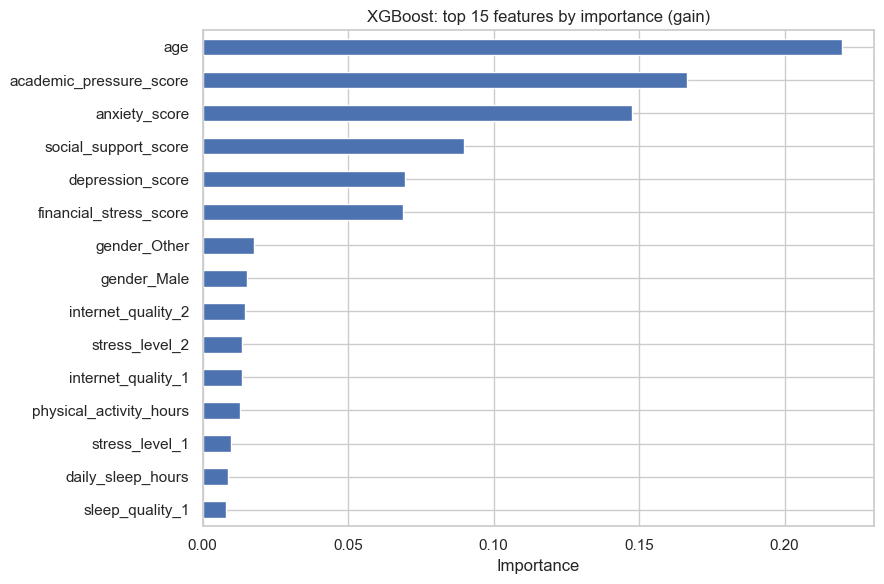

In [15]:
best = results.index[0]
xgb = models["XGBoost"]
imp = pd.Series(xgb.feature_importances_, index=X.columns).sort_values(ascending=True).tail(15)
fig, ax = plt.subplots(figsize=(9, 6))
imp.plot(kind="barh", color="#4C72B0", ax=ax)
ax.set_title("XGBoost: top 15 features by importance (gain)"); ax.set_xlabel("Importance")
plt.tight_layout(); save(fig, "feature_importance"); plt.show()

## 8. Summary

In [16]:
base = results.loc["Majority-class baseline"]
models_only = results.drop(index="Majority-class baseline")
print(f"ROC-AUC across all 11 models: {models_only['ROC-AUC'].min():.3f} – {models_only['ROC-AUC'].max():.3f}  (0.5 = chance)")
print(f"Best accuracy: {models_only['Accuracy'].max():.4f} ({models_only['Accuracy'].idxmax()})  vs. "
      f"majority-class baseline {base['Accuracy']:.4f}")
print(f"Precision of every model ≈ {models_only['Precision'].mean():.3f} = share of at-risk students in the test set "
      f"({y_test.mean():.3f})")

ROC-AUC across all 11 models: 0.496 – 0.502  (0.5 = chance)
Best accuracy: 0.6598 (Random Forest)  vs. majority-class baseline 0.6649
Precision of every model ≈ 0.664 = share of at-risk students in the test set (0.665)


### Conclusions
1. **The labels are independent of the features.** The statistical tests find no significant association, the class-conditional means are virtually identical, and every classifier, from Naive Bayes to XGBoost, has ROC-AUC ≈ 0.50.
2. **High accuracy here is an illusion.** The models with the highest accuracy (about 66%) simply predict *at risk* for almost everyone (recall ≈ 0.98). They match the majority-class baseline and do not beat it.
3. **SMOTE doesn't create signal.** Rebalancing changes *where* models put their threshold, which trades recall for accuracy, but it cannot make an uninformative feature informative.
4. **Lesson:** always report a trivial baseline and a threshold-free metric like ROC-AUC, and check feature–label association before tuning models. The dataset is most likely synthetic with randomly assigned labels. A real study would need data where burnout is actually measured, for example with the Maslach Burnout Inventory.